# EMQA_L3_ms_regime

**Romanian daily base price and the smoothed probability of the turbulent regime of a two-regime Markov-switching model (switching mean and variance) on the daily EUR/MWh shocks, 2019-01-01 to 2026-10-31: the energy crisis was one long turbulent regime, 2026 moves in and out.**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_ms_regime/EMQA_L3_ms_regime.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## Two volatility regimes

$u_t=\mu_{s_t}+\sigma_{s_t}\eta_t$, $s_t\in\{\text{calm},\text{turbulent}\}$ a two-state Markov chain (Hamilton, 1989), estimated by maximum likelihood with 20 random starting values (seed fixed). The chart shows the smoothed probability $\Pr(s_t=\text{turbulent}\mid u_1,\dots,u_T)$.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
E_EUR, M_EUR = mean_fit(u)       # shocks u_t, EUR/MWh
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


### Numbers on the slide

In [6]:
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
np.random.seed(20261106)
ms = MarkovRegression(E_EUR.values, k_regimes=2, trend='c', switching_variance=True).fit(search_reps=20, disp=False)
s2 = ms.params[-2:]
hi = int(np.argmax(s2))                                  # turbulent = regime with the larger variance
PT = ms.regime_transition[:, :, 0]                        # PT[i, j] = Pr(s_t = i | s_{t-1} = j)
ph = pd.Series(ms.smoothed_marginal_probabilities[:, hi], index=E_EUR.index)
slide('std. dev. of shocks, turbulent regime', 'ms.eur.sd_hi', np.sqrt(s2[hi]), 1)
slide('std. dev. of shocks, calm regime', 'ms.eur.sd_lo', np.sqrt(s2[1 - hi]), 1)
slide('expected duration of the turbulent regime, days', 'ms.eur.dur_hi', 1 / (1 - PT[hi, hi]), 1)
on = (ph > 0.5).astype(int)
g = (on.diff() != 0).cumsum()
spells = on.groupby(g).agg(['first', 'size'])
idx = on[g == spells[spells['first'] == 1]['size'].idxmax()].index
slide('longest turbulent spell, start', 'ms.eur.longest_start', str(idx[0].date()))
slide('longest turbulent spell, end', 'ms.eur.longest_end', str(idx[-1].date()))
slide('longest turbulent spell, days', 'ms.eur.longest_days', int(len(idx)))
for y in [2022, 2025, 2026]:
    slide(f'share of turbulent days in {y}, %', f'ms.eur.by_year.{y}', 100 * (ph[ph.index.year == y] > 0.5).mean(), 0)
slide('share of turbulent days since 1 July 2026, %', 'ms.eur.share_2026_q3q4', 100 * (ph.loc['2026-07-01':] > 0.5).mean(), 0)
slide('probability at the cut-off', 'ms.eur.last_prob', ph.iloc[-1], 2)

std. dev. of shocks, turbulent regime                      41.9   [ms.eur.sd_hi]
std. dev. of shocks, calm regime                           12.9   [ms.eur.sd_lo]
expected duration of the turbulent regime, days            23.0   [ms.eur.dur_hi]
longest turbulent spell, start                             2022-06-15   [ms.eur.longest_start]
longest turbulent spell, end                               2023-01-31   [ms.eur.longest_end]
longest turbulent spell, days                              231   [ms.eur.longest_days]
share of turbulent days in 2022, %                         86.0   [ms.eur.by_year.2022]
share of turbulent days in 2025, %                         6.0   [ms.eur.by_year.2025]
share of turbulent days in 2026, %                         33.0   [ms.eur.by_year.2026]
share of turbulent days since 1 July 2026, %               48.0   [ms.eur.share_2026_q3q4]
probability at the cut-off                                 0.47   [ms.eur.last_prob]


### Chart

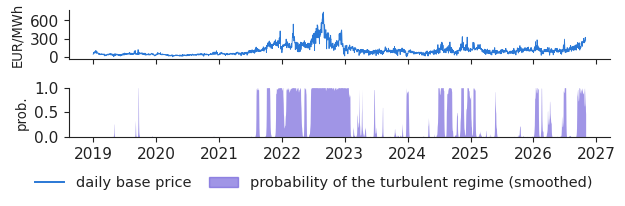

In [7]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
MON = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


def yfmt(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def mfmt(ax, step=1):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=step))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, p: MON[mdates.num2date(v).month - 1] +
                                               (f'\n{mdates.num2date(v).year}' if mdates.num2date(v).month == 1 or p == 0 else '')))
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.1), sharex=True, gridspec_kw={'height_ratios': [1, 1]})
axs[0].plot(P.index, P.values, color=PAL['RO'], lw=0.6)
axs[0].set_ylabel('EUR/MWh', fontsize=9.5)
axs[1].fill_between(ph.index, 0, ph.values, color=C_EUR, alpha=0.6, lw=0)
axs[1].set_ylabel('prob.', fontsize=9.5)
axs[1].set_ylim(0, 1)
axs[1].set_yticks([0, 0.5, 1])
axs[0].yaxis.set_major_locator(MaxNLocator(3))
yfmt(axs[1])
legend_bottom(fig, handles=[plt.Line2D([], [], color=PAL['RO']), Patch(color=C_EUR, alpha=0.6)],
              labels=['daily base price', 'probability of the turbulent regime (smoothed)'], ncol=2)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig('ms_regime.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()